# CP1 – EDA Awal (Track E: Leksikal vs Semantik)
**12S4054 Sistem Rekomendasi – Amazon Reviews 2023, Musical Instruments 5-core**

Seluruh statistik di notebook ini dihitung **hanya dari data training** (kecuali bagian protokol validation), sesuai aturan anti-leakage.
Atur `DATA_DIR` ke folder tempat `MAIN DATA/` dan `SUPPORTING_DATA/` diekstrak.

In [1]:
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "/Users/graciapardede/kuliah/SisRek/Data Sisrek"                       # ubah sesuai lokasi data
MAIN = os.path.join(DATA_DIR, "MAIN DATA")
SUP  = os.path.join(DATA_DIR, "SUPPORTING_DATA")
FIG  = "figures"; os.makedirs(FIG, exist_ok=True)
SEED = 42

train = pd.read_csv(os.path.join(MAIN, "interactions_train.csv"))
val   = pd.read_csv(os.path.join(MAIN, "interactions_validation.csv"))
items = pd.read_csv(os.path.join(MAIN, "items.csv"))
cand  = pd.read_csv(os.path.join(MAIN, "candidate_items_warm.csv"))
val_warm = pd.read_csv(os.path.join(SUP, "interactions_validation_warm.csv"))
eval_users = pd.read_csv(os.path.join(SUP, "evaluable_users_validation_warm.csv"))
print(train.shape, val.shape, items.shape, cand.shape, val_warm.shape, eval_users.shape)

Matplotlib is building the font cache; this may take a moment.


(427957, 4) (41284, 4) (23582, 8) (22753, 1) (30360, 4) (11659, 1)


## 1. Statistik dasar data training

In [2]:
n_users, n_items, n_inter = train.user_id.nunique(), train.item_id.nunique(), len(train)
density = n_inter / (n_users * n_items)
summary = pd.DataFrame({
    "Statistik": ["#Users", "#Items", "#Interaksi", "Density", "Sparsity",
                  "Rata-rata interaksi/user", "Median interaksi/user",
                  "Rata-rata interaksi/item", "Median interaksi/item",
                  "Duplikat (user,item)", "Item_id train yang punya metadata"],
    "Nilai": [n_users, n_items, n_inter, f"{density:.4%}", f"{1-density:.4%}",
              round(n_inter/n_users, 2), train.groupby('user_id').size().median(),
              round(n_inter/n_items, 2), train.groupby('item_id').size().median(),
              int(train.duplicated(['user_id','item_id']).sum()),
              f"{train.item_id.drop_duplicates().isin(items.item_id).mean():.2%}"]})
summary

,Statistik,Nilai
0,#Users,54483
1,#Items,22753
2,#Interaksi,427957
3,Density,0.0345%
4,Sparsity,99.9655%
5,Rata-rata interaksi/user,7.85
6,Median interaksi/user,6.0
7,Rata-rata interaksi/item,18.81
8,Median interaksi/item,8.0
9,"Duplikat (user,item)",0


## 2. Distribusi rating dan definisi relevansi (rating ≥ 4)

,jumlah,proporsi
rating,,
1.0,17486,0.0409
2.0,14335,0.0335
3.0,28578,0.0668
4.0,64120,0.1498
5.0,303438,0.7090


Proporsi interaksi positif (rating>=4): 85.89%


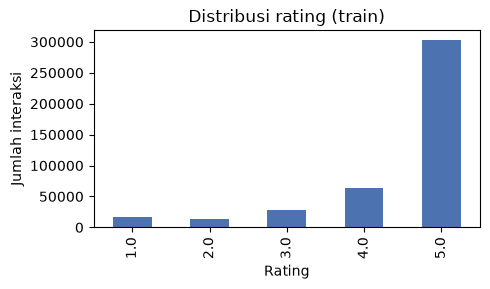

In [3]:
rc = train.rating.value_counts().sort_index()
display(pd.DataFrame({"jumlah": rc, "proporsi": (rc/rc.sum()).round(4)}))
print(f"Proporsi interaksi positif (rating>=4): {(train.rating>=4).mean():.2%}")
ax = rc.plot(kind="bar", color="#4C72B0", figsize=(5,3)); ax.set_xlabel("Rating"); ax.set_ylabel("Jumlah interaksi")
ax.set_title("Distribusi rating (train)"); plt.tight_layout(); plt.savefig(f"{FIG}/rating_dist.png", dpi=200); plt.show()

## 3. Rentang waktu split (temporal, tidak diacak)

In [4]:
for name, d in [("train", train), ("validation", val)]:
    t = pd.to_datetime(d.timestamp, unit="ms")
    print(f"{name:<11} {t.min()}  →  {t.max()}")

train       2003-05-26 23:26:44  →  2021-08-11 00:51:30.562000
validation  2021-08-11 01:04:21.248000  →  2022-07-16 20:16:39.736000


## 4. Aktivitas user (penting untuk analisis user dengan riwayat sedikit)

count    54483.00
mean         7.85
std          6.55
min          1.00
25%          5.00
50%          6.00
75%          9.00
max        270.00
dtype: float64
0.25     5.0
0.50     6.0
0.75     9.0
0.90    13.0
0.99    34.0
dtype: float64
User dengan ≤5 interaksi train: 40.59%


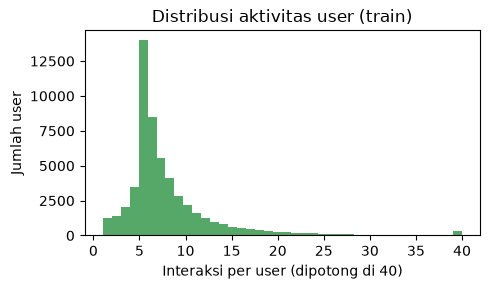

In [5]:
uc = train.groupby("user_id").size()
print(uc.describe().round(2)); print(uc.quantile([.25,.5,.75,.9,.99]))
print(f"User dengan ≤5 interaksi train: {(uc<=5).mean():.2%}")
fig, ax = plt.subplots(figsize=(5,3))
ax.hist(uc.clip(upper=40), bins=40, color="#55A868"); ax.set_xlabel("Interaksi per user (dipotong di 40)")
ax.set_ylabel("Jumlah user"); ax.set_title("Distribusi aktivitas user (train)")
plt.tight_layout(); plt.savefig(f"{FIG}/user_activity.png", dpi=200); plt.show()

## 5. Popularitas item dan long tail

count    22753.00
mean        18.81
std         48.23
min          1.00
25%          5.00
50%          8.00
75%         17.00
max       2272.00
dtype: float64
Top 20% item menguasai 65.01% interaksi
50% interaksi berasal dari 9.44% item teratas


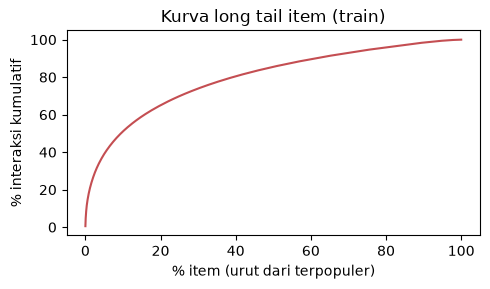

In [6]:
ic = train.groupby("item_id").size().sort_values(ascending=False)
share = ic.cumsum() / ic.sum()
print(ic.describe().round(2))
print(f"Top 20% item menguasai {share.iloc[int(0.2*len(ic))-1]:.2%} interaksi")
print(f"50% interaksi berasal dari {(share<=0.5).mean():.2%} item teratas")
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(np.arange(1, len(share)+1)/len(share)*100, share.values*100, color="#C44E52")
ax.set_xlabel("% item (urut dari terpopuler)"); ax.set_ylabel("% interaksi kumulatif"); ax.set_title("Kurva long tail item (train)")
plt.tight_layout(); plt.savefig(f"{FIG}/long_tail.png", dpi=200); plt.show()

## 6. Protokol warm-start pada validation

In [7]:
pos_warm = val_warm[val_warm.rating >= 4]
proto = pd.DataFrame({
  "Statistik": ["Interaksi validation (semua)", "User validation", "Item validation",
                "% user validation yang ada di train", "% item validation yang ada di train",
                "Interaksi validation warm", "Interaksi warm relevan (rating≥4)",
                "Evaluable users (warm)", "Candidate items (warm)"],
  "Nilai": [len(val), val.user_id.nunique(), val.item_id.nunique(),
            f"{val.user_id.isin(uc.index).mean():.2%}", f"{val.item_id.isin(ic.index).mean():.2%}",
            len(val_warm), len(pos_warm), len(eval_users), len(cand)]})
proto

,Statistik,Nilai
0,Interaksi validation (semua),41284
1,User validation,15748
2,Item validation,11381
3,% user validation yang ada di train,81.47%
4,% item validation yang ada di train,89.65%
5,Interaksi validation warm,30360
6,Interaksi warm relevan (rating≥4),24707
7,Evaluable users (warm),11659
8,Candidate items (warm),22753


## 7. Evaluable users per kelompok riwayat (rencana analisis Track E)
Batas kelompok (1–4, 5–9, ≥10) masih **sementara** dan akan dibekukan pada CP3.

In [8]:
eu = uc.reindex(eval_users.user_id)
groups = pd.cut(eu, [0, 4, 9, np.inf], labels=["Rendah (1–4)", "Sedang (5–9)", "Tinggi (≥10)"])
g = groups.value_counts().sort_index()
pd.DataFrame({"evaluable users": g, "proporsi": (g/g.sum()).round(4)})

,evaluable users,proporsi
Rendah (1–4),4772,0.4093
Sedang (5–9),4142,0.3553
Tinggi (≥10),2745,0.2354


## 8. Kelengkapan metadata dan panjang teks item (input TF-IDF & embedding)

,kolom,% kosong
0,title,0.01
1,store,0.44
2,categories,3.22
3,features,5.53
4,description,25.98
5,content_text_basic,0.00


count    23582.0
mean       186.7
std        207.7
min          4.0
25%         84.0
50%        144.0
75%        236.0
max      11261.0
Name: content_text_basic, dtype: float64
0.1     50.0
0.5    144.0
0.9    356.0
Name: content_text_basic, dtype: float64


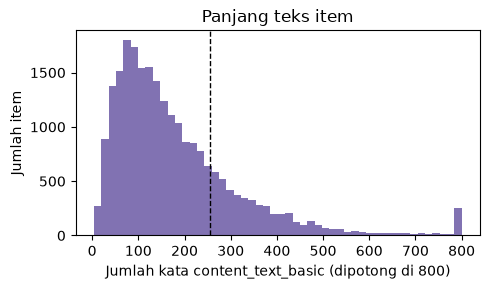

Item dengan >256 kata: 21.46%


In [9]:
def is_empty(s): 
    s = s.fillna("").astype(str).str.strip(); return s.isin(["", "[]", "nan"])
fields = ["title", "store", "categories", "features", "description", "content_text_basic"]
display(pd.DataFrame({"kolom": fields, "% kosong": [round(100*is_empty(items[f]).mean(), 2) for f in fields]}))
words = items.content_text_basic.fillna("").str.split().str.len()
print(words.describe().round(1)); print(words.quantile([.1, .5, .9]))
fig, ax = plt.subplots(figsize=(5,3))
ax.hist(words.clip(upper=800), bins=50, color="#8172B2"); ax.axvline(256, ls="--", c="k", lw=1)
ax.set_xlabel("Jumlah kata content_text_basic (dipotong di 800)"); ax.set_ylabel("Jumlah item")
ax.set_title("Panjang teks item"); plt.tight_layout(); plt.savefig(f"{FIG}/text_length.png", dpi=200); plt.show()
print(f"Item dengan >256 kata: {(words>256).mean():.2%}")

## 9. Distribusi kategori (level-2)

In [10]:
def lvl2(x):
    c = json.loads(x) if isinstance(x, str) else []
    return c[1] if len(c) > 1 else "(tidak ada)"
cat2 = items[items.item_id.isin(ic.index)].categories.apply(lvl2).value_counts()
print("Jumlah kategori level-2:", cat2.size)
cat2.head(12)

Jumlah kategori level-2: 31


categories
Instrument Accessories            10875
Live Sound & Stage                 2408
Microphones & Accessories          1903
Amplifiers & Effects               1667
Studio Recording Equipment         1366
Guitars                             987
Drums & Percussion                  771
(tidak ada)                         748
Electronic Music, DJ & Karaoke      602
Ukuleles, Mandolins & Banjos        364
Wind & Woodwind Instruments         356
Keyboards & MIDI                    267
Name: count, dtype: int64